<a href="https://colab.research.google.com/github/sanoop070/nasa-exoplanet-finder/blob/main/exoplanet_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================
# NASA EXOPLANET FINDER
# Project: Exoplanet Transit Detection using 1D CNN
# Data Source: NASA Kepler Mission
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

import lightkurve as lk

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("All libraries imported successfully!")
print("Lightkurve version:", lk.__version__)
print("PyTorch version:", torch.__version__)

All libraries imported successfully!
Lightkurve version: 2.6.0
PyTorch version: 2.14.1+cpu


/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


In [ ]:
!pip install lightkurve

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 41.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 48.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 54.8 MB/s  0:00:00
  Created wheel for fbpca: filename=fbpca-1.0-py3-none-any.whl size=11429 sha256=c90d69e91f8607ce8e1fc4446cbaf4d071a7c78ad5db416e4cc7b7a1e20d1a2a
  Stored in directory: /root/.cache/pip/wheels/30/85/d4/289ba063a9ae0ba3189c6914e992722575868b2cb41100401b
  Created wheel for memoization: filename=memoization-0.4.0-py3-none-any.whl size=50537 sha256=3df3940de5159832b3e5808d53e1c3e09377b8a0f6bd53037493ade921b9d880
  Stored in directory: /root/.cache/pip/wheels/5c/ef/65/c51178502ccdadab909ffa9339a9a897019

## 02. NASA Kepler Data Collection


In [4]:

# ============================================
# NASA KEPLER DATA COLLECTION
# ============================================

# Search NASA archive for Kepler-10 observations

search_result = lk.search_lightcurve(
    "Kepler-10",
    mission="Kepler"
)

print("Total data products found:", len(search_result))
print(search_result)


Total data products found: 50
SearchResult containing 50 data products.

 #       mission      year   author   exptime         target_name          distance
                                         s                                  arcsec 
--- ----------------- ---- ---------- ------- ---------------------------- --------
  0 Kepler Quarter 02 2009     Kepler      60                kplr011904151      0.0
  1 Kepler Quarter 03 2009     Kepler      60                kplr011904151      0.0
  2 Kepler Quarter 03 2009     Kepler      60                kplr011904151      0.0
  3 Kepler Quarter 03 2009     Kepler      60                kplr011904151      0.0
  4 Kepler Quarter 00 2009     Kepler    1800                kplr011904151      0.0
  5 Kepler Quarter 01 2009     Kepler    1800                kplr011904151      0.0
  6 Kepler Quarter 02 2009     Kepler    1800                kplr011904151      0.0
  7 Kepler Quarter 03 2009     Kepler    1800                kplr011904151      0.0
  8

In [5]:

# ============================================
# 03. FILTER KEPLER LONG-CADENCE DATA
# ============================================

exposure_seconds = np.asarray(
    search_result.table["exptime"],
    dtype=float
)

authors = np.asarray(
    search_result.table["author"]
)

mask = (
    (exposure_seconds == 1800) &
    (authors == "Kepler")
)

long_cadence = search_result[mask]

print("Kepler long-cadence observations:", len(long_cadence))
print(long_cadence)



Kepler long-cadence observations: 15
SearchResult containing 15 data products.

 #       mission      year author exptime  target_name  distance
                                     s                   arcsec 
--- ----------------- ---- ------ ------- ------------- --------
  0 Kepler Quarter 00 2009 Kepler    1800 kplr011904151      0.0
  1 Kepler Quarter 01 2009 Kepler    1800 kplr011904151      0.0
  2 Kepler Quarter 02 2009 Kepler    1800 kplr011904151      0.0
  3 Kepler Quarter 03 2009 Kepler    1800 kplr011904151      0.0
  4 Kepler Quarter 04 2010 Kepler    1800 kplr011904151      0.0
  5 Kepler Quarter 05 2010 Kepler    1800 kplr011904151      0.0
  6 Kepler Quarter 06 2010 Kepler    1800 kplr011904151      0.0
  7 Kepler Quarter 07 2010 Kepler    1800 kplr011904151      0.0
  8 Kepler Quarter 09 2011 Kepler    1800 kplr011904151      0.0
  9 Kepler Quarter 10 2011 Kepler    1800 kplr011904151      0.0
 10 Kepler Quarter 11 2012 Kepler    1800 kplr011904151      0.0
 11 Kepler

In [6]:

# ============================================
# 04. DOWNLOAD KEPLER OBSERVATION
# ============================================

lc = long_cadence[0].download()

print("Download successful!")
print(lc)
print("Data points:", len(lc))


Download successful!
       time             flux      ...   pos_corr1      pos_corr2   
                    electron / s  ...      pix            pix      
------------------ -------------- ... -------------- --------------
 120.5391465105713  5.0146684e+05 ...  1.7792054e-03  3.3286733e-03
120.55958073025249  5.0141212e+05 ...  1.9566093e-03  3.5631030e-03
120.58001484981651  5.0140281e+05 ...  2.0698714e-03  3.4072644e-03
120.60044916937477  5.0135972e+05 ...  2.4259784e-03  3.0491522e-03
120.62088338893955  5.0144759e+05 ...  2.7262936e-03  3.2327282e-03
120.64131750838715  5.0142422e+05 ...  2.8024365e-03  2.5497559e-03
120.66175172782823  5.0134612e+05 ...  2.9968296e-03  2.9109719e-03
120.68218604727736  5.0136928e+05 ...  2.9321318e-03  2.7981971e-03
120.70262016672496  5.0140212e+05 ...  2.9108874e-03  2.8240951e-03
               ...            ... ...            ...            ...
130.06148738515185  5.0152938e+05 ... -4.6389936e-03 -7.1408441e-03
130.08192158433667  5.01570

In [7]:

# ============================================
# 04. DOWNLOAD KEPLER OBSERVATION
# ============================================

# Download Quarter 00
lc = long_cadence[0].download()

print("Download successful!")
print(lc)

print("Total data points:", len(lc))


Download successful!
       time             flux      ...   pos_corr1      pos_corr2   
                    electron / s  ...      pix            pix      
------------------ -------------- ... -------------- --------------
 120.5391465105713  5.0146684e+05 ...  1.7792054e-03  3.3286733e-03
120.55958073025249  5.0141212e+05 ...  1.9566093e-03  3.5631030e-03
120.58001484981651  5.0140281e+05 ...  2.0698714e-03  3.4072644e-03
120.60044916937477  5.0135972e+05 ...  2.4259784e-03  3.0491522e-03
120.62088338893955  5.0144759e+05 ...  2.7262936e-03  3.2327282e-03
120.64131750838715  5.0142422e+05 ...  2.8024365e-03  2.5497559e-03
120.66175172782823  5.0134612e+05 ...  2.9968296e-03  2.9109719e-03
120.68218604727736  5.0136928e+05 ...  2.9321318e-03  2.7981971e-03
120.70262016672496  5.0140212e+05 ...  2.9108874e-03  2.8240951e-03
               ...            ... ...            ...            ...
130.06148738515185  5.0152938e+05 ... -4.6389936e-03 -7.1408441e-03
130.08192158433667  5.01570

<Figure size 1200x500 with 0 Axes>

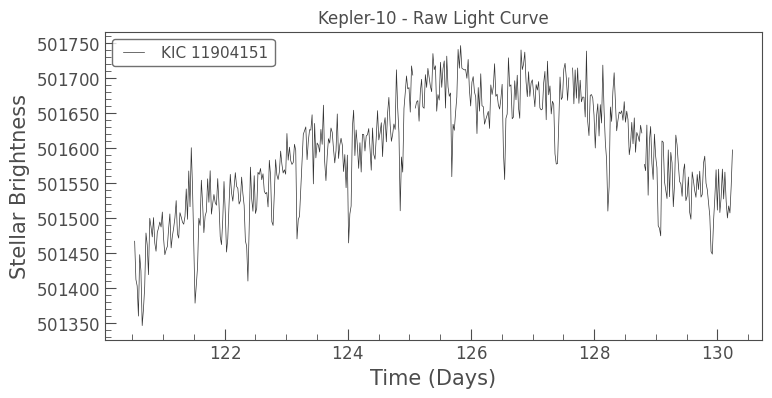

In [8]:

# ============================================
# 05. RAW LIGHT CURVE VISUALIZATION
# ============================================

plt.figure(figsize=(12, 5))

lc.plot()

plt.title("Kepler-10 - Raw Light Curve")
plt.xlabel("Time (Days)")
plt.ylabel("Stellar Brightness")

plt.show()


In [9]:

# ============================================
# DATA CLEANING
# ============================================

# Remove missing values
lc_clean = lc.remove_nans()

# Remove statistical outliers
lc_clean = lc_clean.remove_outliers()

print("Original data points:", len(lc))
print("Cleaned data points:", len(lc_clean))

# Normalize stellar brightness
lc_normalized = lc_clean.normalize()

print("Normalization completed!")
print(lc_normalized)


Original data points: 473
Cleaned data points: 469
Normalization completed!
       time             flux      ...   pos_corr1      pos_corr2   
                                  ...      pix            pix      
------------------ -------------- ... -------------- --------------
 120.5391465105713  9.9973410e-01 ...  1.7792054e-03  3.3286733e-03
120.55958073025249  9.9962503e-01 ...  1.9566093e-03  3.5631030e-03
120.58001484981651  9.9960643e-01 ...  2.0698714e-03  3.4072644e-03
120.60044916937477  9.9952054e-01 ...  2.4259784e-03  3.0491522e-03
120.62088338893955  9.9969572e-01 ...  2.7262936e-03  3.2327282e-03
120.64131750838715  9.9964911e-01 ...  2.8024365e-03  2.5497559e-03
120.66175172782823  9.9949342e-01 ...  2.9968296e-03  2.9109719e-03
120.68218604727736  9.9953961e-01 ...  2.9321318e-03  2.7981971e-03
120.70262016672496  9.9960506e-01 ...  2.9108874e-03  2.8240951e-03
               ...            ... ...            ...            ...
130.06148738515185  9.9985874e-01 ... -4

<Figure size 1200x500 with 0 Axes>

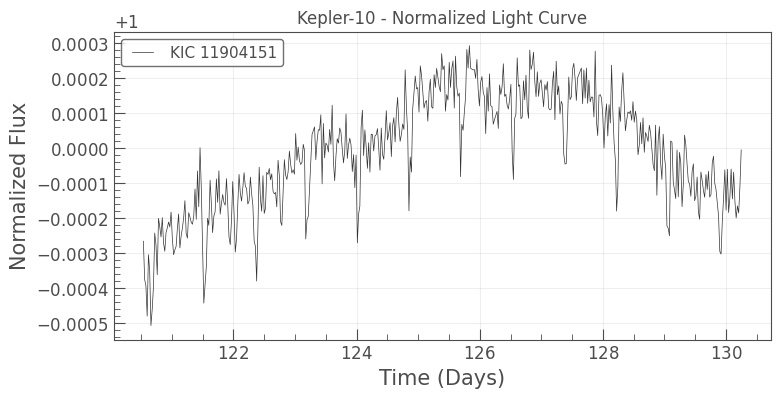

In [10]:

# ============================================
# NORMALIZED LIGHT CURVE
# ============================================

plt.figure(figsize=(12, 5))

lc_normalized.plot()

plt.title("Kepler-10 - Normalized Light Curve")
plt.xlabel("Time (Days)")
plt.ylabel("Normalized Flux")

plt.grid(alpha=0.2)
plt.show()


In [11]:

# ============================================
# DETRENDING THE LIGHT CURVE
# ============================================

lc_flat = lc_normalized.flatten(
    window_length=101,
    polyorder=2
)

print("Detrending completed!")
print("Original data points:", len(lc_normalized))
print("Detrended data points:", len(lc_flat))


Detrending completed!
Original data points: 469
Detrended data points: 469


<Figure size 1400x500 with 0 Axes>

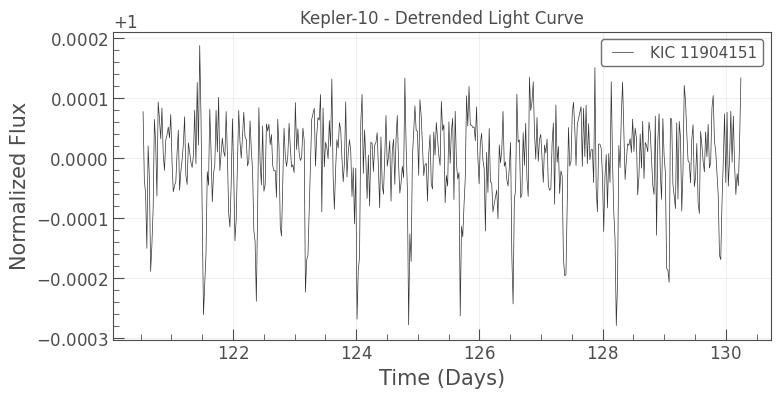

In [12]:

# ============================================
# DETRENDED LIGHT CURVE
# ============================================

plt.figure(figsize=(14, 5))

lc_flat.plot()

plt.title("Kepler-10 - Detrended Light Curve")
plt.xlabel("Time (Days)")
plt.ylabel("Normalized Flux")

plt.grid(alpha=0.2)
plt.show()


In [13]:

# ============================================
# BOX LEAST SQUARES - TRANSIT SEARCH
# ============================================

from astropy.timeseries import BoxLeastSquares

# Extract time and flux
time = lc_flat.time.value
flux = lc_flat.flux.value

# Remove invalid values
valid = np.isfinite(time) & np.isfinite(flux)

time = time[valid]
flux = flux[valid]

# Create BLS model
bls_model = BoxLeastSquares(time, flux)

# Search orbital periods from 0.5 to 2 days
periods = np.arange(0.5, 2.0, 0.0005)

# Test transit durations (days)
durations = np.arange(0.5, 4.0, 0.5) / 24

# Perform period search
bls_result = bls_model.power(
    periods,
    durations
)

# Find strongest signal
best_index = np.argmax(bls_result.power)

best_period = bls_result.period[best_index]
best_duration = bls_result.duration[best_index]
best_depth = bls_result.depth[best_index]

print("BLS search completed!")
print("Best candidate period:", best_period, "days")
print("Transit duration:", best_duration * 24, "hours")
print("Transit depth:", best_depth)


BLS search completed!
Best candidate period: 0.8394999999999626 days
Transit duration: 1.5 hours
Transit depth: 0.00018471477392245327


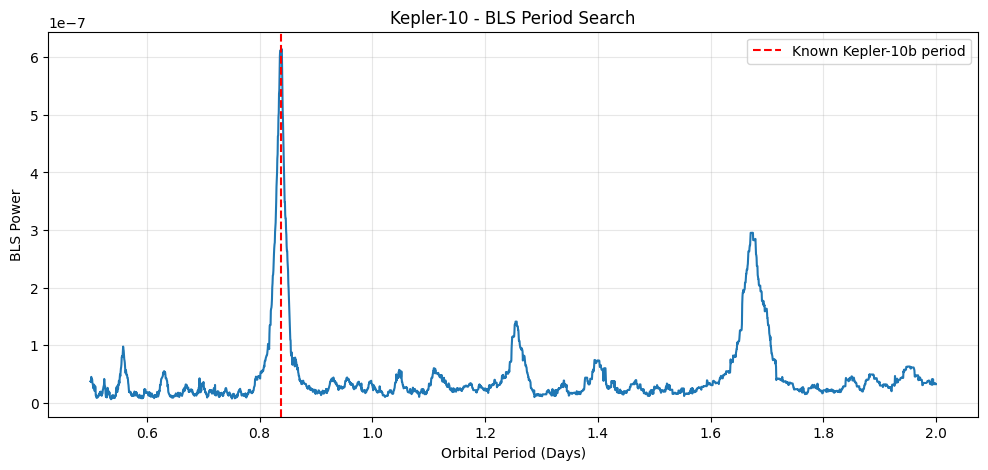

In [14]:

# ============================================
# BLS PERIODOGRAM
# ============================================

plt.figure(figsize=(12, 5))

plt.plot(
    bls_result.period,
    bls_result.power
)

plt.axvline(
    0.8375,
    color="red",
    linestyle="--",
    label="Known Kepler-10b period"
)

plt.title("Kepler-10 - BLS Period Search")
plt.xlabel("Orbital Period (Days)")
plt.ylabel("BLS Power")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


Phase folding completed!
Orbital period: 0.8394999999999626 days


<Figure size 1200x500 with 0 Axes>

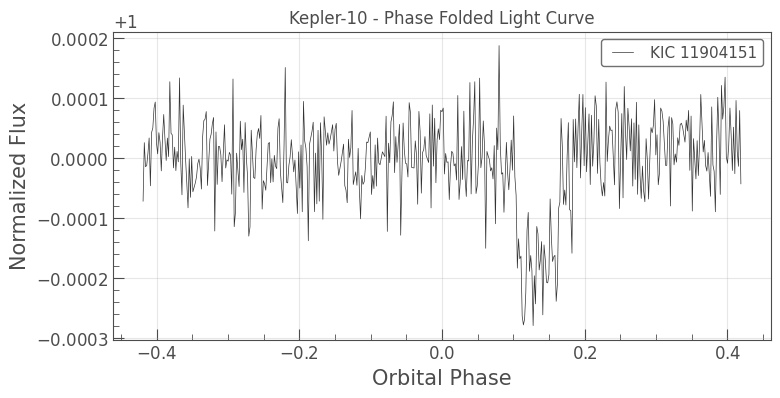

In [15]:

# ============================================
# PHASE FOLDING
# ============================================

folded_lc = lc_flat.fold(
    period=best_period
)

print("Phase folding completed!")
print("Orbital period:", best_period, "days")

# Plot phase-folded light curve
plt.figure(figsize=(12, 5))

folded_lc.plot()

plt.title("Kepler-10 - Phase Folded Light Curve")
plt.xlabel("Orbital Phase")
plt.ylabel("Normalized Flux")

plt.grid(alpha=0.3)
plt.show()


10. Transit Alignment


Orbital period: 0.8394999999999626
Estimated transit midpoint: 120.67456317723797


<Figure size 1200x500 with 0 Axes>

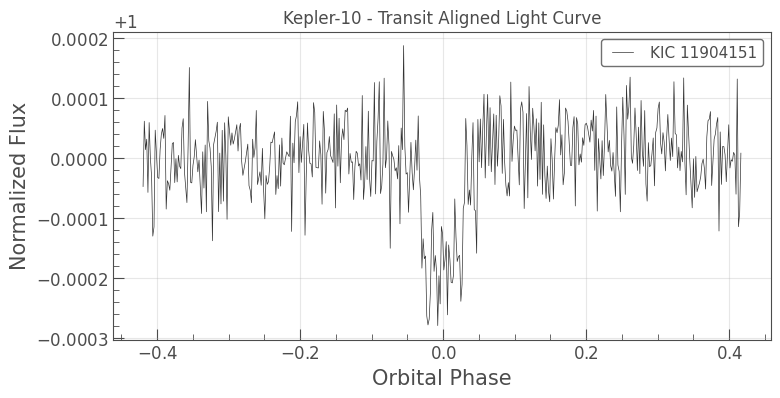

In [16]:

# ============================================
# TRANSIT ALIGNMENT
# ============================================

# Find strongest BLS signal
best_index = np.argmax(bls_result.power)

# Get estimated transit midpoint
best_transit_time = bls_result.transit_time[best_index]

print("Orbital period:", best_period)
print("Estimated transit midpoint:", best_transit_time)

# Fold around the estimated transit midpoint
folded_aligned = lc_flat.fold(
    period=best_period,
    epoch_time=best_transit_time
)

# Plot aligned light curve
plt.figure(figsize=(12, 5))

folded_aligned.plot()

plt.title("Kepler-10 - Transit Aligned Light Curve")
plt.xlabel("Orbital Phase")
plt.ylabel("Normalized Flux")

plt.grid(alpha=0.3)
plt.show()


11. Refining the Orbital Period

In [18]:

# ============================================
# REFINED BLS PERIOD SEARCH
# ============================================

# Search more precisely around our candidate
refined_periods = np.linspace(
    0.82, 0.86, 2001
)

refined_result = bls_model.power(
    refined_periods,
    durations
)

# Find refined best period
refined_index = np.argmax(refined_result.power)

refined_period = refined_result.period[refined_index]

print("Original period:", best_period)
print("Refined period:", refined_period, "days")

print(
    "Known Kepler-10b period:",
    0.8375,
    "days"
)


Original period: 0.8394999999999626
Refined period: 0.8391 days
Known Kepler-10b period: 0.8375 days


Download All Kepler Observations

In [19]:

# ============================================
# DOWNLOAD ALL 15 KEPLER QUARTERS
# ============================================

# Download all selected long-cadence observations
lc_collection = long_cadence.download_all()

print("Download completed!")
print("Number of downloaded light curves:", len(lc_collection))

for i, light_curve in enumerate(lc_collection):
    print(
        f"Quarter {i + 1}:",
        len(light_curve),
        "observations"
    )


Download completed!
Number of downloaded light curves: 15
Quarter 1: 473 observations
Quarter 2: 1626 observations
Quarter 3: 4075 observations
Quarter 4: 4140 observations
Quarter 5: 1011 observations
Quarter 6: 4492 observations
Quarter 7: 4276 observations
Quarter 8: 4229 observations
Quarter 9: 4618 observations
Quarter 10: 4447 observations
Quarter 11: 4480 observations
Quarter 12: 4252 observations
Quarter 13: 4344 observations
Quarter 14: 4446 observations
Quarter 15: 1286 observations


12. Full Dataset Preprocessing and Stitching

In [20]:

# ============================================
# PROCESS ALL 15 KEPLER QUARTERS
# ============================================

processed_quarters = []

for i, quarter in enumerate(lc_collection):

    # Remove missing values
    clean = quarter.remove_nans()

    # Remove statistical outliers
    clean = clean.remove_outliers()

    # Normalize each quarter
    normalized = clean.normalize()

    # Remove long-term trends
    flattened = normalized.flatten(
        window_length=101,
        polyorder=2
    )

    processed_quarters.append(flattened)

    print(
        f"Quarter {i+1}: "
        f"{len(quarter)} -> {len(flattened)} observations"
    )

print("\nAll quarters processed successfully!")


Quarter 1: 473 -> 469 observations
Quarter 2: 1626 -> 1617 observations
Quarter 3: 4075 -> 4067 observations
Quarter 4: 4140 -> 4133 observations
Quarter 5: 1011 -> 1008 observations
Quarter 6: 4492 -> 4482 observations
Quarter 7: 4276 -> 4258 observations
Quarter 8: 4229 -> 4220 observations
Quarter 9: 4618 -> 4608 observations
Quarter 10: 4447 -> 4438 observations
Quarter 11: 4480 -> 4473 observations
Quarter 12: 4252 -> 4240 observations
Quarter 13: 4344 -> 4269 observations
Quarter 14: 4446 -> 4360 observations
Quarter 15: 1286 -> 1285 observations

All quarters processed successfully!


Full dataset created!
Total processed observations: 51927


<Figure size 1500x600 with 0 Axes>

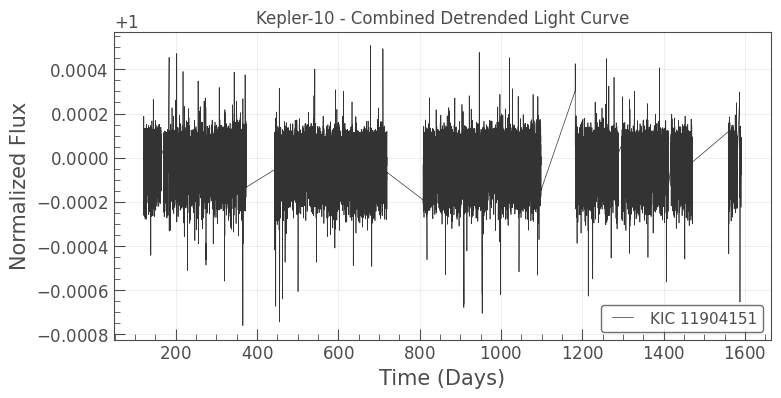

In [21]:

# ============================================
# STITCH ALL PROCESSED QUARTERS
# ============================================

processed_collection = lk.LightCurveCollection(
    processed_quarters
)

lc_full = processed_collection.stitch()

print("Full dataset created!")
print("Total processed observations:", len(lc_full))

# Plot combined light curve
plt.figure(figsize=(15, 6))

lc_full.plot()

plt.title("Kepler-10 - Combined Detrended Light Curve")
plt.xlabel("Time (Days)")
plt.ylabel("Normalized Flux")

plt.grid(alpha=0.2)
plt.show()


13. Full Dataset Visualization

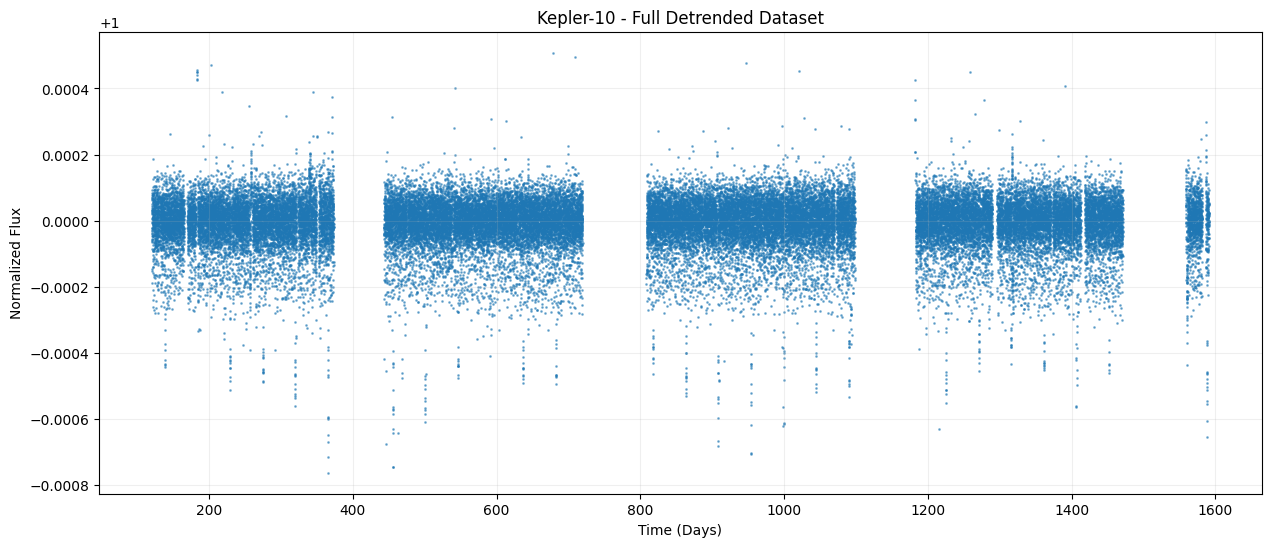

Total observations: 51927
Observation start: 120.5391465105713
Observation end: 1591.0016788740104


In [22]:

# ============================================
# FULL DATASET - SCATTER VISUALIZATION
# ============================================

plt.figure(figsize=(15, 6))

plt.scatter(
    lc_full.time.value,
    lc_full.flux.value,
    s=1,
    alpha=0.5
)

plt.title("Kepler-10 - Full Detrended Dataset")
plt.xlabel("Time (Days)")
plt.ylabel("Normalized Flux")

plt.grid(alpha=0.2)
plt.show()

print("Total observations:", len(lc_full))
print("Observation start:", np.min(lc_full.time.value))
print("Observation end:", np.max(lc_full.time.value))


14. Full Dataset Box Least Squares Search

In [23]:

# ============================================
# FULL DATASET - BLS PERIOD SEARCH
# ============================================

from astropy.timeseries import BoxLeastSquares

# Extract full dataset
full_time = lc_full.time.value
full_flux = lc_full.flux.value

# Remove invalid values
valid = np.isfinite(full_time) & np.isfinite(full_flux)

full_time = full_time[valid]
full_flux = full_flux[valid]

# Create BLS model
full_bls = BoxLeastSquares(full_time, full_flux)

# Search orbital periods
full_periods = np.arange(
    0.5,
    2.0,
    0.0001
)

# Test transit durations
full_durations = np.arange(
    0.5,
    4.0,
    0.5
) / 24

# Run BLS
full_result = full_bls.power(
    full_periods,
    full_durations
)

# Find strongest signal
full_best_index = np.argmax(full_result.power)

full_best_period = full_result.period[full_best_index]
full_best_duration = full_result.duration[full_best_index]
full_best_depth = full_result.depth[full_best_index]

print("FULL DATASET BLS COMPLETED!")
print("Best candidate period:", full_best_period, "days")
print("Transit duration:", full_best_duration * 24, "hours")
print("Transit depth:", full_best_depth)


FULL DATASET BLS COMPLETED!
Best candidate period: 0.8374999999999628 days
Transit duration: 2.0 hours
Transit depth: 0.00014957215161886888


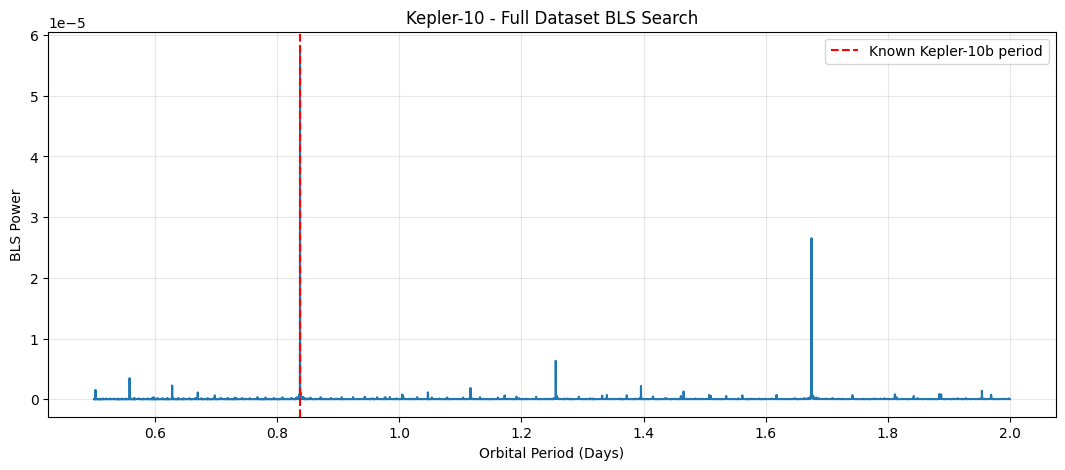

In [24]:

# ============================================
# FULL DATASET BLS PERIODOGRAM
# ============================================

plt.figure(figsize=(13, 5))

plt.plot(
    full_result.period,
    full_result.power
)

plt.axvline(
    0.8375,
    color="red",
    linestyle="--",
    label="Known Kepler-10b period"
)

plt.title("Kepler-10 - Full Dataset BLS Search")
plt.xlabel("Orbital Period (Days)")
plt.ylabel("BLS Power")

plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [25]:

# ============================================
# VERIFY THE TRUE BLS PEAK
# ============================================

power = np.asarray(full_result.power)
periods = np.asarray(full_result.period)
durations_found = np.asarray(full_result.duration)

print("Power shape:", power.shape)
print("Period shape:", periods.shape)
print("Duration shape:", durations_found.shape)

# Identify the strongest peak
peak_index = np.unravel_index(
    np.nanargmax(power),
    power.shape
)

# Handle both single and multiple duration results
if periods.shape == power.shape:
    actual_period = periods[peak_index]
else:
    actual_period = periods[peak_index[0]]

if durations_found.shape == power.shape:
    actual_duration = durations_found[peak_index]
elif durations_found.ndim == 1:
    actual_duration = durations_found[
        peak_index[-1] if power.ndim > 1 else peak_index[0]
    ]
else:
    actual_duration = durations_found.item()

print("\nVERIFIED BLS RESULTS")
print("--------------------")
print("Strongest period:", actual_period, "days")
print("Strongest duration:", actual_duration * 24, "hours")
print("Maximum BLS power:", power[peak_index])
print("Known Kepler-10b period: 0.8375 days")


Power shape: (15000,)
Period shape: (15000,)
Duration shape: (15000,)

VERIFIED BLS RESULTS
--------------------
Strongest period: 0.8374999999999628 days
Strongest duration: 2.0 hours
Maximum BLS power: 5.766338806158684e-05
Known Kepler-10b period: 0.8375 days


15. Full Dataset Phase Folding

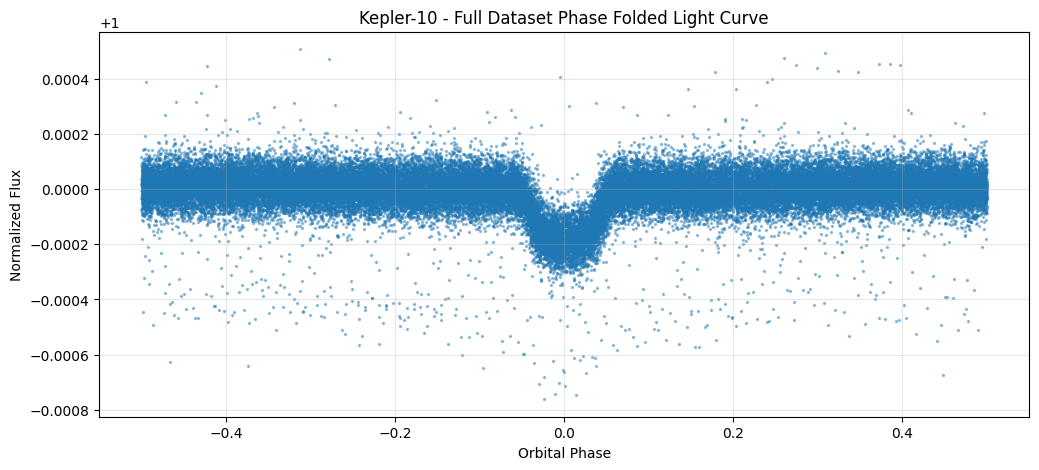

Full dataset phase folding completed!
Orbital period: 0.8374999999999628 days
Observations: 51927


In [26]:

# ============================================
# FULL DATASET - PHASE FOLDING
# ============================================

# Get best-fit transit epoch
best_full_epoch = full_result.transit_time[
    full_best_index
]

# Fold the complete dataset
full_folded_lc = lc_full.fold(
    period=full_best_period,
    epoch_time=best_full_epoch
)

# Convert folded time to orbital phase
phase = full_folded_lc.time.value / full_best_period
flux = full_folded_lc.flux.value

# Plot
plt.figure(figsize=(12, 5))

plt.scatter(
    phase,
    flux,
    s=2,
    alpha=0.4
)

plt.title("Kepler-10 - Full Dataset Phase Folded Light Curve")
plt.xlabel("Orbital Phase")
plt.ylabel("Normalized Flux")

plt.grid(alpha=0.3)
plt.show()

print("Full dataset phase folding completed!")
print("Orbital period:", full_best_period, "days")
print("Observations:", len(full_folded_lc))


16. Individual Quarter Transit Validation

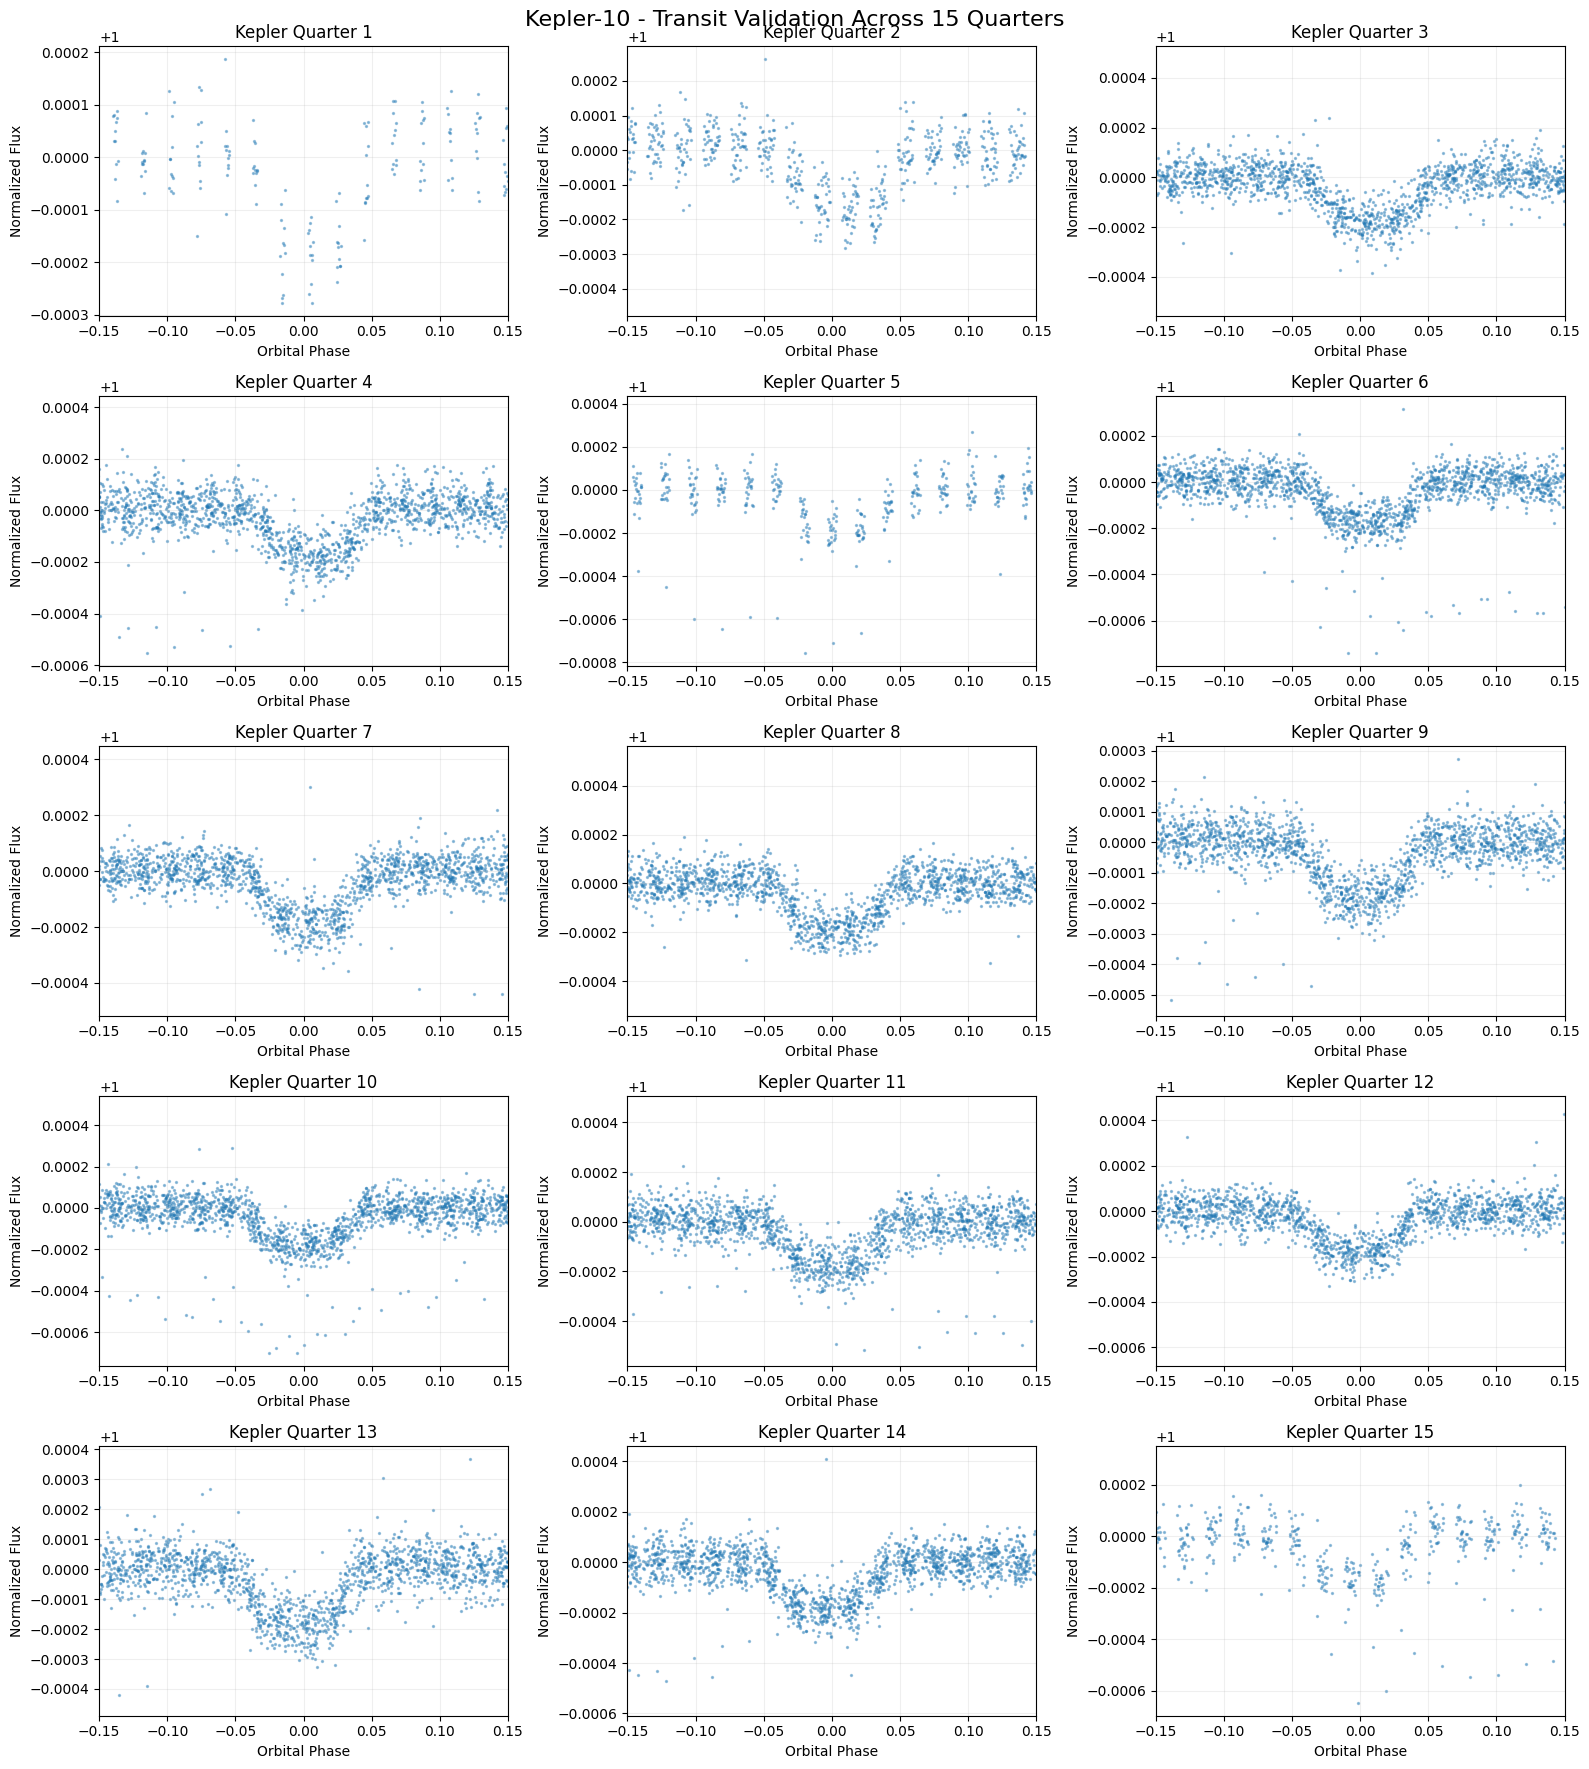

In [27]:

# ============================================
# INDIVIDUAL QUARTER TRANSIT VALIDATION
# ============================================

fig, axes = plt.subplots(
    5, 3,
    figsize=(16, 18)
)

axes = axes.flatten()

for i, quarter in enumerate(processed_quarters):

    # Fold each quarter using the recovered period
    folded = quarter.fold(
        period=full_best_period,
        epoch_time=best_full_epoch
    )

    phase = folded.time.value
    flux = folded.flux.value

    axes[i].scatter(
        phase,
        flux,
        s=2,
        alpha=0.4
    )

    axes[i].set_title(f"Kepler Quarter {i+1}")
    axes[i].set_xlim(-0.15, 0.15)
    axes[i].grid(alpha=0.2)

    axes[i].set_xlabel("Orbital Phase")
    axes[i].set_ylabel("Normalized Flux")

plt.suptitle(
    "Kepler-10 - Transit Validation Across 15 Quarters",
    fontsize=16
)

plt.tight_layout()
plt.show()


17. Quarter-wise Transit Depth Analysis

In [28]:


# ============================================
# QUARTER-WISE TRANSIT DEPTH ANALYSIS
# ============================================

import pandas as pd

quarter_results = []

# Expected transit half-width in orbital phase
half_width = (
    full_best_duration / (2 * full_best_period)
)

for i, quarter in enumerate(processed_quarters):

    folded = quarter.fold(
        period=full_best_period,
        epoch_time=best_full_epoch
    )

    phase = folded.time.value / full_best_period
    flux = folded.flux.value

    # Transit and baseline regions
    in_transit = np.abs(phase) <= half_width

    out_of_transit = (
        (np.abs(phase) > 0.10) &
        (np.abs(phase) < 0.40)
    )

    transit_flux = flux[in_transit]
    baseline_flux = flux[out_of_transit]

    if len(transit_flux) > 0 and len(baseline_flux) > 0:

        depth = (
            np.median(baseline_flux) -
            np.median(transit_flux)
        )

        quarter_results.append({
            "Quarter": i + 1,
            "Transit Observations": len(transit_flux),
            "Baseline Observations": len(baseline_flux),
            "Transit Depth (PPM)": depth * 1e6
        })

results_df = pd.DataFrame(quarter_results)

print(results_df.to_string(index=False))


 Quarter  Transit Observations  Baseline Observations Transit Depth (PPM)
       1                    48                    284  173.79052536714568
       2                   157                    974  145.79386517543645
       3                   395                   2451  155.20892206311032
       4                   410                   2478  154.19797537341572
       5                   105                    598  160.11496675560898
       6                   449                   2682  149.46309435626137
       7                   424                   2557  153.81462111874188
       8                   420                   2526  164.55388942659965
       9                   451                   2762  158.34126051617048
      10                   445                   2662  156.43926411446074
      11                   438                   2694   154.6907429703648
      12                   417                   2550  154.79465892520582
      13                   433        

18. Transit Depth Consistency Across Quarters

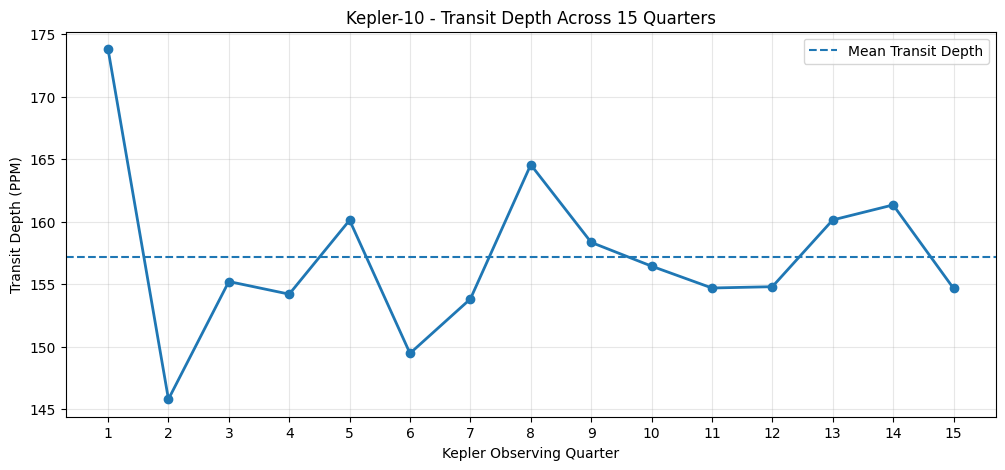

In [29]:

# ============================================
# TRANSIT DEPTH CONSISTENCY
# ============================================

plt.figure(figsize=(12, 5))

plt.plot(
    results_df["Quarter"],
    results_df["Transit Depth (PPM)"],
    marker="o",
    linewidth=2
)

plt.axhline(
    results_df["Transit Depth (PPM)"].mean(),
    linestyle="--",
    label="Mean Transit Depth"
)

plt.title("Kepler-10 - Transit Depth Across 15 Quarters")
plt.xlabel("Kepler Observing Quarter")
plt.ylabel("Transit Depth (PPM)")

plt.xticks(range(1, 16))
plt.grid(alpha=0.3)
plt.legend()
plt.show()


19. Transit Window Sensitivity Analysis

In [30]:

# ============================================
# TRANSIT WINDOW SENSITIVITY ANALYSIS
# ============================================

window_hours = [1.0, 1.5, 2.0, 2.5, 3.0]

sensitivity_results = []

for hours in window_hours:

    half_width = (
        (hours / 24) / (2 * full_best_period)
    )

    depths = []

    for quarter in processed_quarters:

        folded = quarter.fold(
            period=full_best_period,
            epoch_time=best_full_epoch
        )

        phase = folded.time.value / full_best_period
        flux = folded.flux.value

        in_transit = np.abs(phase) <= half_width

        out_of_transit = (
            (np.abs(phase) > 0.10) &
            (np.abs(phase) < 0.40)
        )

        if np.any(in_transit) and np.any(out_of_transit):

            depth = (
                np.median(flux[out_of_transit])
                - np.median(flux[in_transit])
            ) * 1e6

            depths.append(depth)

    sensitivity_results.append({
        "Window (hours)": hours,
        "Mean Depth (PPM)": np.mean(depths),
        "Std Depth (PPM)": np.std(depths)
    })

sensitivity_df = pd.DataFrame(sensitivity_results)

print(sensitivity_df.to_string(index=False))


 Window (hours)  Mean Depth (PPM)  Std Depth (PPM)
            1.0        185.889801         6.591776
            1.5        175.712731         9.010232
            2.0        157.155678         6.315580
            2.5        133.191980         5.398389
            3.0        107.958449         4.984390


20. Download NASA Kepler KOI Catalogue

In [31]:

# ============================================
# NASA KEPLER KOI CATALOGUE
# ============================================

import requests
import pandas as pd
from io import StringIO

# NASA Exoplanet Archive TAP query
query = """
SELECT
    kepid,
    kepoi_name,
    kepler_name,
    koi_disposition,
    koi_period,
    koi_time0bk,
    koi_duration,
    koi_depth,
    koi_score,
    koi_fpflag_nt,
    koi_fpflag_ss,
    koi_fpflag_co,
    koi_fpflag_ec
FROM cumulative
WHERE koi_disposition IN (
    'CONFIRMED',
    'CANDIDATE',
    'FALSE POSITIVE'
)
"""

url = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"

response = requests.get(
    url,
    params={
        "query": query,
        "format": "csv"
    },
    timeout=120
)

response.raise_for_status()

# Load catalogue
koi_df = pd.read_csv(StringIO(response.text))

print("NASA KOI catalogue downloaded!")
print("Total KOI records:", len(koi_df))

print("\nDisposition distribution:")
print(koi_df["koi_disposition"].value_counts())

print(
    "\nUnique target stars:",
    koi_df["kepid"].nunique()
)

print("\nFirst five records:")
display(koi_df.head())


NASA KOI catalogue downloaded!
Total KOI records: 9564

Disposition distribution:
koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2748
CANDIDATE         1977
Name: count, dtype: int64

Unique target stars: 8214

First five records:


,kepid,kepoi_name,kepler_name,koi_disposition,koi_period,koi_time0bk,koi_duration,koi_depth,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec
0,10797460,K00752.01,Kepler-227 b,CONFIRMED,9.488036,170.538750,2.95750,615.8,1.000,0,0,0,0
1,10797460,K00752.02,Kepler-227 c,CONFIRMED,54.418383,162.513840,4.50700,874.8,0.969,0,0,0,0
2,10811496,K00753.01,NaN,CANDIDATE,19.899140,175.850252,1.78220,10829.0,0.000,0,0,0,0
3,10848459,K00754.01,NaN,FALSE POSITIVE,1.736952,170.307565,2.40641,8079.2,0.000,0,1,0,0
4,10854555,K00755.01,Kepler-664 b,CONFIRMED,2.525592,171.595550,1.65450,603.3,1.000,0,0,0,0


21. Dataset Cleaning and Label Preparation

In [32]:

# ============================================
# DATASET CLEANING AND LABEL PREPARATION
# ============================================

# Keep only confirmed planets and false positives
df = koi_df[
    koi_df["koi_disposition"].isin(
        ["CONFIRMED", "FALSE POSITIVE"]
    )
].copy()

# Create binary labels
df["label"] = (
    df["koi_disposition"] == "CONFIRMED"
).astype(int)

# Required astronomical measurements
required_columns = [
    "kepid",
    "koi_period",
    "koi_time0bk",
    "koi_duration",
    "koi_depth"
]

# Remove records with missing measurements
df = df.dropna(subset=required_columns)

# Remove physically invalid measurements
df = df[
    (df["koi_period"] > 0) &
    (df["koi_duration"] > 0) &
    (df["koi_depth"] > 0)
]

# Remove duplicate KOI records
df = df.drop_duplicates(
    subset=["kepoi_name"]
)

# Reset index
df = df.reset_index(drop=True)

print("DATASET CLEANING COMPLETED")
print("---------------------------")

print("Total usable records:", len(df))

print("\nClass distribution:")
print(df["label"].value_counts())

print("\nUnique target stars:", df["kepid"].nunique())

print("\nMissing values:")
print(df[required_columns].isnull().sum())

print("\nDataset preview:")
display(df.head())

# Save cleaned catalogue
df.to_csv(
    "kepler_cleaned_catalogue.csv",
    index=False
)

print("\nCleaned catalogue saved successfully!")


DATASET CLEANING COMPLETED
---------------------------
Total usable records: 7328

Class distribution:
label
0    4582
1    2746
Name: count, dtype: int64

Unique target stars: 6424

Missing values:
kepid           0
koi_period      0
koi_time0bk     0
koi_duration    0
koi_depth       0
dtype: int64

Dataset preview:


,kepid,kepoi_name,kepler_name,koi_disposition,koi_period,koi_time0bk,koi_duration,koi_depth,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,label
0,10797460,K00752.01,Kepler-227 b,CONFIRMED,9.488036,170.538750,2.95750,615.8,1.000,0,0,0,0,1
1,10797460,K00752.02,Kepler-227 c,CONFIRMED,54.418383,162.513840,4.50700,874.8,0.969,0,0,0,0,1
2,10848459,K00754.01,NaN,FALSE POSITIVE,1.736952,170.307565,2.40641,8079.2,0.000,0,1,0,0,0
3,10854555,K00755.01,Kepler-664 b,CONFIRMED,2.525592,171.595550,1.65450,603.3,1.000,0,0,0,0,1
4,10872983,K00756.01,Kepler-228 d,CONFIRMED,11.094321,171.201160,4.59450,1517.5,1.000,0,0,0,0,1



Cleaned catalogue saved successfully!


22. Select Kepler Targets for Light Curve Download

In [33]:

# ============================================
# SELECT LABELLED KEPLER TARGETS
# ============================================

# Keep a manageable pilot dataset
MAX_TARGETS_PER_CLASS = 30

# Separate positive and negative examples
positive_targets = (
    df[df["label"] == 1]
    .drop_duplicates(subset=["kepid"])
    .head(MAX_TARGETS_PER_CLASS)
)

negative_targets = (
    df[df["label"] == 0]
    .drop_duplicates(subset=["kepid"])
    .head(MAX_TARGETS_PER_CLASS)
)

# Combine both classes
pilot_df = pd.concat(
    [positive_targets, negative_targets],
    ignore_index=True
)

print("Pilot dataset prepared!")
print("Confirmed planet targets:", len(positive_targets))
print("False positive targets:", len(negative_targets))
print("Total unique targets:", pilot_df["kepid"].nunique())

display(
    pilot_df[
        ["kepid", "kepoi_name", "koi_disposition", "label"]
    ].head(10)
)


Pilot dataset prepared!
Confirmed planet targets: 30
False positive targets: 30
Total unique targets: 60


,kepid,kepoi_name,koi_disposition,label
0,10797460,K00752.01,CONFIRMED,1
1,10854555,K00755.01,CONFIRMED,1
2,10872983,K00756.01,CONFIRMED,1
3,10910878,K00757.01,CONFIRMED,1
4,11446443,K00001.01,CONFIRMED,1
5,10666592,K00002.01,CONFIRMED,1
6,6922244,K00010.01,CONFIRMED,1
7,10984090,K00112.02,CONFIRMED,1
8,10526549,K00746.01,CONFIRMED,1
9,10583066,K00747.01,CONFIRMED,1


23. Download Pilot Kepler Light Curves

In [34]:

# ============================================
# DOWNLOAD PILOT LIGHT CURVES
# ============================================

import lightkurve as lk
import time

downloaded_curves = []
download_log = []

for i, row in pilot_df.iterrows():

    kepid = int(row["kepid"])
    label = int(row["label"])

    try:
        search = lk.search_lightcurve(
            f"KIC {kepid}",
            mission="Kepler",
            cadence="long"
        )

        if len(search) == 0:
            print(f"No data found: {kepid}")
            continue

        # Download available Kepler observations
        curves = search.download_all()

        if curves is None or len(curves) == 0:
            print(f"Download unavailable: {kepid}")
            continue

        downloaded_curves.append({
            "kepid": kepid,
            "label": label,
            "curves": curves
        })

        download_log.append({
            "kepid": kepid,
            "label": label,
            "status": "Success",
            "quarters": len(curves)
        })

        print(f"Downloaded KIC {kepid}: {len(curves)} quarters")

    except Exception as e:

        download_log.append({
            "kepid": kepid,
            "label": label,
            "status": str(e),
            "quarters": 0
        })

        print(f"Error downloading {kepid}: {e}")

    time.sleep(0.3)

download_df = pd.DataFrame(download_log)

print("\nDOWNLOAD SUMMARY")
print(download_df["status"].value_counts())


Downloaded KIC 10797460: 17 quarters
Downloaded KIC 10854555: 16 quarters
Downloaded KIC 10872983: 13 quarters
Downloaded KIC 10910878: 14 quarters
Downloaded KIC 11446443: 15 quarters
Downloaded KIC 10666592: 18 quarters
Downloaded KIC 6922244: 18 quarters
Downloaded KIC 10984090: 18 quarters
Downloaded KIC 10526549: 17 quarters
Downloaded KIC 10583066: 17 quarters
Downloaded KIC 10601284: 17 quarters
Downloaded KIC 10662202: 17 quarters
Downloaded KIC 10682541: 13 quarters
Downloaded KIC 11460018: 17 quarters
Downloaded KIC 11507101: 17 quarters
Downloaded KIC 10987985: 13 quarters
Downloaded KIC 11018648: 14 quarters
Downloaded KIC 11138155: 17 quarters
Downloaded KIC 11153539: 14 quarters
Downloaded KIC 9579641: 18 quarters
Downloaded KIC 11304958: 17 quarters
Downloaded KIC 11391957: 14 quarters
Downloaded KIC 11403044: 16 quarters
Downloaded KIC 11414511: 17 quarters
Downloaded KIC 12110942: 17 quarters
Downloaded KIC 12366084: 17 quarters
Downloaded KIC 12404086: 17 quarters
Dow